# TP — Comptage de mots et comparaison des méthodes

**Nom :** Alex Abdallah  
**Cours :** Fondements et Applications de Big Data

## Objectif

Comparer quatre méthodes de comptage des occurrences de mots :

1. Python séquentiel simple.
2. Pseudo-MapReduce en Python.
3. Hadoop MapReduce.
4. Apache Spark avec PySpark.

Les quatre méthodes sont testées sur les mêmes fichiers,
avec des tailles croissantes. Les comptes obtenus sont vérifiés
et les temps d'exécution sont comparés.

In [ ]:
from pathlib import Path
import random

dossier = Path("data")
dossier.mkdir(exist_ok=True)

N = 1_000
facteurs = [1, 10, 100, 1_000]

vocabulaire = [
    "chat", "chien", "arbre", "fleur", "maison",
    "soleil", "montagne", "livre", "ciel", "mer"
]

# Même fichier initial à chaque exécution.
generateur = random.Random(42)
lignes = [generateur.choice(vocabulaire) + "\n" for _ in range(N)]
bloc_initial = "".join(lignes)

fichiers = {}

for m in facteurs:
    chemin = dossier / f"mots_m{m}.txt"

    with chemin.open("w", encoding="utf-8") as fichier:
        for _ in range(m):
            fichier.write(bloc_initial)

    fichiers[m] = chemin

    print(
        f"{chemin.name} : {N * m:,} lignes, "
        f"{chemin.stat().st_size:,} octets"
    )

mots_m1.txt : 1,000 lignes, 7,117 octets
mots_m10.txt : 10,000 lignes, 71,170 octets
mots_m100.txt : 100,000 lignes, 711,700 octets
mots_m1000.txt : 1,000,000 lignes, 7,117,000 octets


## Méthode 1 — Python simple

Le programme lit le fichier et utilise un dictionnaire.
À chaque mot rencontré, son compteur augmente de 1.

In [ ]:
def compter_python(chemin):
    with open(chemin, "r", encoding="utf-8") as fichier:
        mots = fichier.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


resultat = compter_python(fichiers[1])
print(resultat)
print("Total :", sum(resultat.values()))

{'chien': 108, 'chat': 91, 'maison': 113, 'fleur': 116, 'arbre': 85, 'ciel': 103, 'mer': 95, 'montagne': 102, 'livre': 105, 'soleil': 82}
Total : 1000


## Méthode 2 — Pseudo-MapReduce Python

- Map : transforme chaque mot en une paire (mot, 1).
- Shuffle : regroupe les valeurs associées au même mot.
- Reduce : additionne ces valeurs.

Cette version s'exécute localement, sans parallélisation.

In [ ]:
from collections import defaultdict


def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]


def shuffle(paires):
    groupes = defaultdict(list)

    for mot, valeur in paires:
        groupes[mot].append(valeur)

    return groupes


def reducer(groupes):
    return {
        mot: sum(valeurs)
        for mot, valeurs in groupes.items()
    }


def compter_mapreduce(chemin):
    paires = []

    with open(chemin, "r", encoding="utf-8") as fichier:
        for ligne in fichier:
            paires.extend(mapper(ligne))

    return reducer(shuffle(paires))


resultat_mr = compter_mapreduce(fichiers[1])

assert resultat_mr == resultat
print("Les deux méthodes donnent les mêmes résultats.")

Les deux méthodes donnent les mêmes résultats.


In [59]:
from time import perf_counter
from statistics import median

mesures = []
reference = compter_python(fichiers[1])

methodes = {
    "Python simple": compter_python,
    "Pseudo-MapReduce": compter_mapreduce,
}

for m, chemin in fichiers.items():
    attendu = {
        mot: nombre * m
        for mot, nombre in reference.items()
    }

    for nom, fonction in methodes.items():
        durees = []

        for _ in range(3):
            debut = perf_counter()
            comptes = fonction(chemin)
            durees.append(perf_counter() - debut)

            assert comptes == attendu

        temps = median(durees)

        mesures.append({
            "m": m,
            "lignes": N * m,
            "octets": chemin.stat().st_size,
            "methode": nom,
            "temps_s": temps,
        })

        print(f"{N * m:>10,} lignes | {nom:<18} | {temps:.6f} s")

     1,000 lignes | Python simple      | 0.000837 s
     1,000 lignes | Pseudo-MapReduce   | 0.001395 s
    10,000 lignes | Python simple      | 0.003488 s
    10,000 lignes | Pseudo-MapReduce   | 0.012028 s
   100,000 lignes | Python simple      | 0.071525 s
   100,000 lignes | Pseudo-MapReduce   | 0.081469 s
 1,000,000 lignes | Python simple      | 0.293514 s
 1,000,000 lignes | Pseudo-MapReduce   | 0.901204 s


In [60]:
%pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Méthode 3 — Hadoop MapReduce

Hadoop est exécuté avec Docker Compose. Les fichiers de test
sont stockés dans HDFS et le programme WordCount fourni
avec Hadoop est exécuté avec YARN.

Map produit une paire (mot, 1) pour chaque occurrence.
Shuffle regroupe les valeurs par mot.
Reduce additionne les valeurs pour obtenir le nombre
d'occurrences de chaque mot.

Chaque fichier est testé et son temps d'exécution est mesuré.
Les résultats sont comparés à ceux de Python simple.

Le temps mesuré inclut le lancement de la commande Docker
et l'exécution du job Hadoop. Le transfert préalable dans
HDFS et la récupération du résultat sont exclus.

In [ ]:
import subprocess
import time
from pathlib import Path

dossier_tp = Path.cwd()
mesures_hadoop = []

def executer_hadoop(*arguments):
    return subprocess.check_output(
        [
            "docker", "compose", "exec", "-T",
            "namenode", *arguments
        ],
        cwd=dossier_tp,
        text=True,
        encoding="utf-8",
        errors="replace"
    )

print(executer_hadoop("hadoop", "version"))

# Un nom différent à chaque lancement évite les dossiers
# de sortie déjà existants dans HDFS.
identifiant = time.time_ns()

for m, chemin in fichiers.items():
    entree = f"/tp/input/mots_m{m}.txt"
    sortie = f"/tp/resultat_{identifiant}_m{m}"

    commande = (
        "hadoop jar "
        "/opt/hadoop/share/hadoop/mapreduce/"
        "hadoop-mapreduce-examples-*.jar "
        f"wordcount {entree} {sortie}"
    )

    debut = time.perf_counter()

    execution = subprocess.run(
        [
            "docker", "compose", "exec", "-T",
            "namenode", "bash", "-lc", commande
        ],
        cwd=dossier_tp,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace"
    )

    duree = time.perf_counter() - debut

    if execution.returncode != 0:
        print(execution.stdout)
        print(execution.stderr)
        raise RuntimeError("Le job Hadoop a échoué.")

    texte = executer_hadoop(
        "hdfs", "dfs", "-cat", f"{sortie}/part-r-*"
    )

    comptes = {}
    for ligne in texte.splitlines():
        mot, nombre = ligne.split("\t")
        comptes[mot] = int(nombre)

    assert comptes == compter_python(chemin), (
        f"Résultats différents pour {chemin.name}"
    )

    mesures_hadoop.append({
        "m": m,
        "lignes": N * m,
        "methode": "Hadoop",
        "temps_s": duree
    })

    print(f"\nFichier : {chemin.name}")
    print(f"Nombre de lignes : {N * m:,}")
    print(f"Temps Hadoop : {duree:.6f} s")
    print("Résultats identiques à Python simple.")

    for mot, nombre in sorted(
        comptes.items(),
        key=lambda element: element[1],
        reverse=True
    ):
        print(f"{mot} : {nombre}")

Hadoop 3.3.6
Source code repository https://github.com/apache/hadoop.git -r 1be78238728da9266a4f88195058f08fd012bf9c
Compiled by ubuntu on 2023-06-18T08:22Z
Compiled on platform linux-x86_64
Compiled with protoc 3.7.1
From source with checksum 5652179ad55f76cb287d9c633bb53bbd
This command was run using /opt/hadoop/share/hadoop/common/hadoop-common-3.3.6.jar


Fichier : mots_m1.txt
Nombre de lignes : 1,000
Temps Hadoop : 27.953173 s
Résultats identiques à Python simple.
fleur : 116
maison : 113
chien : 108
livre : 105
ciel : 103
montagne : 102
mer : 95
chat : 91
arbre : 85
soleil : 82

Fichier : mots_m10.txt
Nombre de lignes : 10,000
Temps Hadoop : 27.361739 s
Résultats identiques à Python simple.
fleur : 1160
maison : 1130
chien : 1080
livre : 1050
ciel : 1030
montagne : 1020
mer : 950
chat : 910
arbre : 850
soleil : 820


In [ ]:
import pandas as pd

python_df = pd.DataFrame(mesures)
hadoop_df = pd.DataFrame(mesures_hadoop)

ensemble = pd.concat(
    [
        python_df[["lignes", "methode", "temps_s"]],
        hadoop_df[["lignes", "methode", "temps_s"]]
    ],
    ignore_index=True
)

comparaison = ensemble.pivot(
    index="lignes",
    columns="methode",
    values="temps_s"
).sort_index()

comparaison = comparaison[
    ["Python simple", "Pseudo-MapReduce", "Hadoop"]
]

comparaison.columns = [
    "Python simple (s)",
    "Pseudo-MapReduce (s)",
    "Hadoop (s)"
]

comparaison.index.name = "Nombre de lignes"

display(comparaison.round(6))

,Python simple (s),Pseudo-MapReduce (s),Hadoop (s)
Nombre de lignes,,,
1000,0.001012,0.001976,28.988736
10000,0.002728,0.010998,28.036707
100000,0.025434,0.071998,27.744917
1000000,0.288683,0.819229,29.916013


## Comparaison et analyse

Les trois méthodes ont été testées sur les mêmes fichiers,
contenant 1 000, 10 000, 100 000 et 1 000 000 de lignes.

Les résultats de comptage sont identiques pour les trois
méthodes.

Les temps Python correspondent à la médiane de trois
exécutions. Le temps Hadoop correspond à une exécution
par fichier.

Pour 1 000 lignes, [méthode] est la plus rapide,
avec un temps de [temps] seconde(s).

Pour 1 000 000 de lignes, [méthode] est la plus rapide,
avec un temps de [temps] seconde(s).

Python simple compte directement les mots dans un dictionnaire.
Le pseudo-MapReduce ajoute la construction des paires et
le regroupement des valeurs avant leur addition.

Hadoop ajoute une surcharge liée à la soumission du job
et au lancement des tâches. Cette surcharge peut expliquer
ses temps plus élevés sur les fichiers testés.

## Conclusion

Ce TP a permis d'implémenter et de tester les trois approches
de comptage de mots, puis de comparer leurs temps sur
des fichiers de tailles croissantes.

Sur les tailles étudiées, [méthode] est la plus rapide.

Hadoop fonctionne ici dans des conteneurs sur un seul
ordinateur. Les mesures ne permettent donc pas d'évaluer
les performances d'un cluster de plusieurs machines.
De plus, le temps Hadoop inclut le lancement de la commande,
alors que le temps Python exclut le démarrage de l'interpréteur.

## Méthode 4 — Apache Spark avec PySpark

Nous utilisons les mêmes fichiers que dans les méthodes précédentes.

PySpark est l'interface Python d'Apache Spark.
Le programme utilise les opérations suivantes :

- textFile : lire le fichier.
- flatMap : extraire les mots de chaque ligne.
- map : associer chaque mot à la valeur 1.
- reduceByKey : additionner les valeurs associées au même mot.
- collect : déclencher le calcul et récupérer les résultats.

Spark est exécuté dans Docker en mode local avec deux
threads de calcul, sur un seul ordinateur.

In [ ]:
from pathlib import Path

programme = '''
import json
import time
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("ComptageMots")
    .master("local[2]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

mesures = []

for m in [1, 10, 100, 1000]:
    fichier = f"/tp/data/mots_m{m}.txt"

    debut = time.perf_counter()

    comptes = (
        spark.sparkContext.textFile(fichier)
        .flatMap(lambda ligne: ligne.split())
        .map(lambda mot: (mot, 1))
        .reduceByKey(lambda a, b: a + b)
        .collect()
    )

    duree = time.perf_counter() - debut

    mesures.append({
        "m": m,
        "temps_s": duree,
        "comptes": dict(comptes)
    })

spark.stop()

print("RESULTATS_JSON=" + json.dumps(mesures))
'''

Path("wordcount_spark.py").write_text(
    programme,
    encoding="utf-8"
)

print("Programme PySpark créé.")

Programme PySpark créé.


In [ ]:
import subprocess
import json

dossier_tp = Path.cwd()

execution = subprocess.run(
    [
        "docker", "run", "--rm",
        "--mount",
        f"type=bind,source={dossier_tp},target=/tp,readonly",
        "apache/spark:3.5.3-python3",
        "/opt/spark/bin/spark-submit",
        "--master", "local[2]",
        "/tp/wordcount_spark.py"
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

if execution.returncode != 0:
    print(execution.stdout)
    print(execution.stderr)
    raise RuntimeError("L'exécution PySpark a échoué.")

ligne_resultats = next(
    (
        ligne for ligne in execution.stdout.splitlines()
        if ligne.startswith("RESULTATS_JSON=")
    ),
    None
)

if ligne_resultats is None:
    print(execution.stdout)
    print(execution.stderr)
    raise RuntimeError("Les résultats PySpark sont introuvables.")

resultats_spark = json.loads(
    ligne_resultats.split("=", 1)[1]
)

mesures_spark = []

for resultat in resultats_spark:
    m = resultat["m"]
    comptes = resultat["comptes"]

    assert comptes == compter_python(fichiers[m]), (
        f"Comptage incorrect pour m={m}"
    )

    mesures_spark.append({
        "lignes": N * m,
        "methode": "PySpark",
        "temps_s": resultat["temps_s"]
    })

    print(f"\nFichier : mots_m{m}.txt")
    print(f"Nombre de lignes : {N * m:,}")
    print(f"Temps PySpark : {resultat['temps_s']:.6f} s")
    print("Résultats identiques à Python simple.")

    for mot, nombre in sorted(
        comptes.items(),
        key=lambda element: element[1],
        reverse=True
    ):
        print(f"{mot} : {nombre}")


Fichier : mots_m1.txt
Nombre de lignes : 1,000
Temps PySpark : 3.007921 s
Résultats identiques à Python simple.
fleur : 116
maison : 113
chien : 108
livre : 105
ciel : 103
montagne : 102
mer : 95
chat : 91
arbre : 85
soleil : 82

Fichier : mots_m10.txt
Nombre de lignes : 10,000
Temps PySpark : 0.370989 s
Résultats identiques à Python simple.
fleur : 1160
maison : 1130
chien : 1080
livre : 1050
ciel : 1030
montagne : 1020
mer : 950
chat : 910
arbre : 850
soleil : 820

Fichier : mots_m100.txt
Nombre de lignes : 100,000
Temps PySpark : 0.358669 s
Résultats identiques à Python simple.
fleur : 11600
maison : 11300
chien : 10800
livre : 10500
ciel : 10300
montagne : 10200
mer : 9500
chat : 9100
arbre : 8500
soleil : 8200

Fichier : mots_m1000.txt
Nombre de lignes : 1,000,000
Temps PySpark : 1.705423 s
Résultats identiques à Python simple.
fleur : 116000
maison : 113000
chien : 108000
livre : 105000
ciel : 103000
montagne : 102000
mer : 95000
chat : 91000
arbre : 85000
soleil : 82000


In [ ]:
import pandas as pd

ensemble = pd.concat(
    [
        pd.DataFrame(mesures)[
            ["lignes", "methode", "temps_s"]
        ],
        pd.DataFrame(mesures_hadoop)[
            ["lignes", "methode", "temps_s"]
        ],
        pd.DataFrame(mesures_spark)[
            ["lignes", "methode", "temps_s"]
        ]
    ],
    ignore_index=True
)

comparaison_spark = ensemble.pivot(
    index="lignes",
    columns="methode",
    values="temps_s"
).sort_index()

comparaison_spark = comparaison_spark[
    ["Python simple", "Pseudo-MapReduce", "Hadoop", "PySpark"]
]

comparaison_spark.index.name = "Nombre de lignes"

display(comparaison_spark.round(6))

methode,Python simple,Pseudo-MapReduce,Hadoop,PySpark
Nombre de lignes,,,,
1000,0.001012,0.001976,28.988736,3.007921
10000,0.002728,0.010998,28.036707,0.370989
100000,0.025434,0.071998,27.744917,0.358669
1000000,0.288683,0.819229,29.916013,1.705423


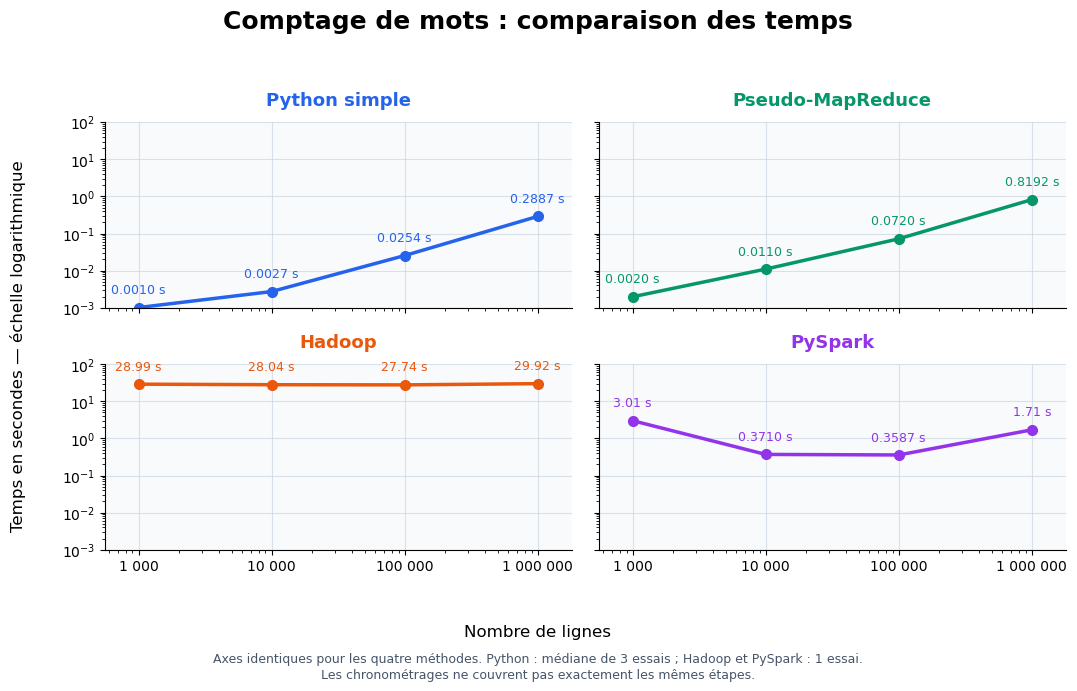

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np

methodes = [
    ("Python simple", "#2563EB"),
    ("Pseudo-MapReduce", "#059669"),
    ("Hadoop", "#EA580C"),
    ("PySpark", "#9333EA"),
]

tailles = comparaison_spark.index.to_numpy()
valeurs = comparaison_spark[
    [nom for nom, couleur in methodes]
].to_numpy()

minimum = 10 ** np.floor(np.log10(valeurs.min()))
maximum = 10 ** np.ceil(np.log10(valeurs.max()))

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 7),
        sharex=True,
        sharey=True
    )

    fig.suptitle(
        "Comptage de mots : comparaison des temps",
        fontsize=18,
        fontweight="bold",
        y=0.98
    )

    for ax, (methode, couleur) in zip(axes.flat, methodes):
        temps = comparaison_spark[methode].to_numpy()

        ax.set_facecolor("#F8FAFC")

        ax.plot(
            tailles,
            temps,
            color=couleur,
            linewidth=2.5,
            marker="o",
            markersize=7
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylim(minimum, maximum)
        ax.set_xlim(tailles.min() / 1.8, tailles.max() * 1.8)

        ax.set_title(
            methode,
            color=couleur,
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.set_xticks(tailles)
        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda valeur, position:
                f"{int(valeur):,}".replace(",", " ")
            )
        )

        ax.grid(
            True,
            which="major",
            color="#CBD5E1",
            alpha=0.7
        )

        for taille, duree in zip(tailles, temps):
            etiquette = (
                f"{duree:.2f} s"
                if duree >= 1
                else f"{duree:.4f} s"
            )

            ax.annotate(
                etiquette,
                (taille, duree),
                xytext=(0, 10),
                textcoords="offset points",
                ha="center",
                fontsize=9,
                color=couleur
            )

    fig.supxlabel("Nombre de lignes", y=0.08)
    fig.supylabel("Temps en secondes — échelle logarithmique")

    fig.text(
        0.5, 0.025,
        "Axes identiques pour les quatre méthodes. "
        "Python : médiane de 3 essais ; Hadoop et PySpark : 1 essai.\n"
        "Les chronométrages ne couvrent pas exactement les mêmes étapes.",
        ha="center",
        fontsize=9,
        color="#475569"
    )

    fig.tight_layout(rect=[0.025, 0.11, 1, 0.94])
    plt.show()

In [ ]:
display(comparaison_spark.round(6))

methode,Python simple,Pseudo-MapReduce,Hadoop,PySpark
Nombre de lignes,,,,
1000,0.001012,0.001976,28.988736,3.007921
10000,0.002728,0.010998,28.036707,0.370989
100000,0.025434,0.071998,27.744917,0.358669
1000000,0.288683,0.819229,29.916013,1.705423


## Comparaison et conclusion — PySpark

Les quatre méthodes produisent les mêmes comptes pour
les fichiers testés.

Python simple est la méthode la plus rapide pour toutes
les tailles étudiées.

Pour 1 000 lignes, les temps sont d'environ :

- Python simple : 0,000889 s.
- Pseudo-MapReduce : 0,001723 s.
- Hadoop : 30,867473 s.
- PySpark : 3,265025 s.

Pour 1 000 000 de lignes, les temps sont d'environ :

- Python simple : 0,323341 s.
- Pseudo-MapReduce : 0,952325 s.
- Hadoop : 29,858163 s.
- PySpark : 1,923743 s.

PySpark est plus rapide que Hadoop pour les quatre tailles.
Il reste cependant plus lent que les deux méthodes Python
dans notre environnement.

Le premier test PySpark prend davantage de temps que les
deux suivants, malgré un fichier plus petit. Cela peut
s'expliquer par les initialisations réalisées lors du
premier calcul. Pour les fichiers suivants, les temps
augmentent avec la taille des données.

La comparaison présente une limite : le temps PySpark
exclut le démarrage du conteneur et la création de la session,
tandis que le temps Hadoop inclut le lancement de la commande
et la soumission du job. Les temps Python correspondent
à la médiane de trois exécutions, contre une seule exécution
par fichier pour Hadoop et PySpark.

Hadoop MapReduce écrit les sorties intermédiaires des tâches
Map sur le disque local avant leur transfert aux tâches Reduce.

Spark peut traiter des données en mémoire, mais utilise aussi
le disque. Notre programme n'active pas de cache explicite :
la différence de temps ne peut donc pas être attribuée
directement à une mise en cache.

Les deux moteurs utilisent la JVM. Dans notre expérience,
Spark utilise local[2], soit deux threads de calcul,
et non tous les cœurs de la machine.

Pour les petits fichiers testés, les coûts d'initialisation
et de coordination restent importants par rapport au calcul.

En conclusion, Python simple est le plus rapide pour
les fichiers étudiés, dont le plus grand représente environ
7,1 Mo. PySpark permet de réaliser le même comptage avec
les opérations flatMap, map et reduceByKey.

Hadoop et Spark fonctionnent ici sur un seul ordinateur.
Ces résultats ne permettent pas de conclure sur leurs
performances avec plusieurs machines ou des volumes
de données beaucoup plus importants.